# CA1 Data Preparation Ciaran Lynch

## Add python libraries to analysis

In [104]:
import pandas as pd
import seaborn as sns
%matplotlib inline  
import matplotlib.pyplot as plt
import numpy as np


### The assignment requires us to carried out analysis of a csv named student_dataV2
###  This csv was also attached with an excel file called student_data_Dictionary.
###  This excel file gave us a description of the variable names listed with a number value and  their associate meaning

In [105]:
dict = pd.read_excel("student_data_dictionary.xlsx")

In [106]:
dict

,Variable Name,Role,Type,Demographic,Description,Units
0,Marital Status,Feature,Integer,Marital Status,1 – single 2 – married 3 – widower 4 – divorce...,NaN
1,Application mode,Feature,Integer,NaN,1 - 1st phase - general contingent 2 - Ordinan...,NaN
2,Application order,Feature,Integer,NaN,Application order (between 0 - first choice; a...,NaN
3,Course,Feature,Integer,NaN,33 - Biofuel Production Technologies 171 - Ani...,NaN
4,Daytime/evening attendance,Feature,Integer,NaN,1 – daytime 0 - evening,NaN
5,Previous qualification,Feature,Integer,Education Level,1 - Secondary education 2 - Higher education -...,NaN
6,Previous qualification (grade),Feature,Continuous,NaN,Grade of previous qualification (between 0 and...,NaN
7,Nacionality,Feature,Integer,Nationality,1 - Portuguese; 2 - German; 6 - Spanish; 11 - ...,NaN
8,Mother's qualification,Feature,Integer,Education Level,1 - Secondary Education - 12th Year of Schooli...,NaN
9,Father's qualification,Feature,Integer,Education Level,1 - Secondary Education - 12th Year of Schooli...,NaN


## Load the Dataset provided called student_dataV2

In [107]:
df = pd.read_csv("student_dataV2.csv")

### Characterisation of the data set

### Check  the data loaded correctly

In [108]:
df.head(5)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17.0,5.0,171.0,1,1,122.0,1,19,12.0,...,0,0.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15.0,1.0,9254.0,1,1,160.0,1,1,3.0,...,0,6.0,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1.0,5.0,9070.0,1,1,122.0,1,37,37.0,...,0,6.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17.0,2.0,9773.0,1,1,122.0,1,38,37.0,...,0,6.0,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39.0,1.0,8014.0,0,1,100.0,1,37,38.0,...,0,6.0,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [109]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   object 
 1   Application mode                                4423 non-null   float64
 2   Application order                               4423 non-null   float64
 3   Course                                          4421 non-null   float64
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4420 non-null   float64
 7   Nacionality                                     4424 non-null   object 
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

In [110]:
df.shape

(4424, 37)

#### We can see that the dataset contains 4424 rows of data and  37 columns
#### and we have a target categorical variable with a classification task
#### (dropout, enrolled, and graduate) at the end of the normal duration of the course

### Rename the columns to make it more readable

In [111]:
df = df.rename(columns={
    "Marital status": "maritial_status",
    "Application mode": "application_mode",
    "Application order": "application_order",
    "Course": "course",
    "Daytime/evening attendance": "course_time",
    "Previous qualification": "previous_qual",
    "Previous qualification (grade)": "previous_grade",
    "Nacionality": "nationality",
    "Mother's qualification": "mothers_qual",
    "Father's qualification": "fathers_qual",
    "Mother's occupation.": "mothers_occupation",
    "Father's occupation": "fathers_occupation",
    "Admission grade": "admission_grade",
    "Educational special needs": "special_needs",
    "Debtor": "debtor",
    "Tuition fees up to date": "tuition_paid",
    "Gender": "gender",
    "Age at enrollment": "enroll_age",
    "International": "international",
    "Curricular units 1st sem (credited)": "1st_sem_credit",
    "Curricular units 1st sem (enrolled)": "1st_sem_enrolled",
    "Curricular units 1st sem (evaluations)": "1st_sem_evaluation",
    "Curricular units 1st sem (approved)": "1st_sem_approved",
    "Curricular units 1st sem (grade)": "1st_sem_grade",
    "Curricular units 1st sem (without evaluations)": "1st_sem_without_eval",
    "Curricular units 2nd sem (credited) ": "2nd_sem_credit",
    "Curricular units 2nd sem (enrolled) ": "2nd_sem_enrolled",
    "Curricular units 2nd sem (evaluations)": "2nd_sem_evaluationn",
    "Curricular units 2nd sem (approved) ": "2nd_sem_approved",
    "Curricular units 2nd sem (grade)": "2nd_sem_grade",
    "Curricular units 2nd sem (without evaluations)": "1st_sem_without_eval",
    "Unemployment rate": "unemployed_rate",
    "Inflation rate": "inflation_rate"
    } 
    )

In [112]:
df.head(3)

,maritial_status,application_mode,application_order,course,course_time,previous_qual,previous_grade,nationality,mothers_qual,fathers_qual,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),2nd_sem_evaluationn,Curricular units 2nd sem (approved),2nd_sem_grade,1st_sem_without_eval,unemployed_rate,inflation_rate,GDP,Target
0,1,17.0,5.0,171.0,1,1,122.0,1,19,12.0,...,0,0.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15.0,1.0,9254.0,1,1,160.0,1,1,3.0,...,0,6.0,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1.0,5.0,9070.0,1,1,122.0,1,37,37.0,...,0,6.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout


In [113]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   maritial_status                      4424 non-null   object 
 1   application_mode                     4423 non-null   float64
 2   application_order                    4423 non-null   float64
 3   course                               4421 non-null   float64
 4   course_time                          4424 non-null   int64  
 5   previous_qual                        4424 non-null   int64  
 6   previous_grade                       4420 non-null   float64
 7   nationality                          4424 non-null   object 
 8   mothers_qual                         4424 non-null   int64  
 9   fathers_qual                         4423 non-null   float64
 10  Mother's occupation                  4423 non-null   float64
 11  fathers_occupation            

## Carry out analysis on variable columns
## Check the Target variable

In [114]:
df["Target"].unique()

array(['Dropout', 'Graduate', 'Enrolled', 'Grad', 'graduate', 'Drop',
       'dropout'], dtype=object)

### See errors in categorising the variables
### These need to be replaced

In [115]:
df["Target"] = df["Target"].replace(
    {
        "Grad": "Graduate",
        "graduate": "Graduate",
        "Drop" : "Dropout",
        "dropout": "Dropout"
    }
)

In [116]:
df["Target"].unique()

array(['Dropout', 'Graduate', 'Enrolled'], dtype=object)

### Check the information on maritial_status

In [117]:
df["maritial_status"].unique()

array(['1', '2', '4', '?', '3', '5', '6'], dtype=object)

### Replace the ? with nan

In [118]:
df["maritial_status"] = df["maritial_status"].replace("?", np.nan)

## Replace the numeric values with the appropriate values per student_data_dictionary

In [119]:
df["maritial_status"] = df["maritial_status"].replace(
    {
        "1": "single",
        "2": "married",
        "3" : "widower",
        "4": "divorced",
        "5" : "facto union",
        "6" : "legally seperated"
    }
)

In [120]:
df["maritial_status"].unique()

array(['single', 'married', 'divorced', nan, 'widower', 'facto union',
       'legally seperated'], dtype=object)

### Carry out analysis of enroll_age

In [121]:
df["enroll_age"].unique()

array(['20', '19', '45', '50', '18', '22', '21', '34', '37', '43', '55',
       '39', '29', '24', '27', '23', '26', '33', '35', '25', '44', '36',
       '47', '28', '38', 'UnKnown', '30', '31', '32', '40', '42', '48',
       '49', '46', '41', '70', '60', '53', '51', '52', '54', '61', '58',
       '59', '17', '57', '62', nan], dtype=object)

#### See the presence of unknown variable
####  replace unknown to nan using numpy

In [122]:
df["enroll_age"] = df["enroll_age"].replace("UnKnown", np.nan)

In [123]:
df["enroll_age"].unique()

array(['20', '19', '45', '50', '18', '22', '21', '34', '37', '43', '55',
       '39', '29', '24', '27', '23', '26', '33', '35', '25', '44', '36',
       '47', '28', '38', nan, '30', '31', '32', '40', '42', '48', '49',
       '46', '41', '70', '60', '53', '51', '52', '54', '61', '58', '59',
       '17', '57', '62'], dtype=object)

In [124]:
# df["enroll_age"] = df["enroll_age"].astype(int)

## Carry Out Analysis of Course Time


In [125]:
df["course_time"].unique()

array([1, 0])

## Change values of variables
### however these rows are listed as an integer, so will need to be changed to a string(object)
###  using the pandas map function

In [126]:
df["course_time"] = df["course_time"].map(
    {
        0 : "evening",
        1: "daytime"
    }
)

In [127]:
df["course_time"].unique()

array(['daytime', 'evening'], dtype=object)

## Carry out analysis of tuition_paid

In [128]:
df["tuition_paid"].unique()

array(['1', '0', nan, '?'], dtype=object)

## replace the ? with nan
## And add in the correct categorical answer
## note this variable is an object so will need to be converted to numeric using pandas pd.to_numeric

In [130]:
df["tuition_paid"] = df["tuition_paid"].replace("?", np.nan)

In [131]:
# change to numeric first
df["tuition_paid"] = pd.to_numeric(df["tuition_paid"])
# then remap values
df["tuition_paid"] = df["tuition_paid"].map(
    {
        0 : "No",
        1 : "Yes"
    }
)

In [132]:
df["tuition_paid"].unique()

array(['Yes', 'No', nan], dtype=object)

In [133]:
df.isnull().sum()

maritial_status                        1
application_mode                       1
application_order                      1
course                                 3
course_time                            0
previous_qual                          0
previous_grade                         4
nationality                            0
mothers_qual                           0
fathers_qual                           1
Mother's occupation                    1
fathers_occupation                     1
admission_grade                        2
Displaced                              0
special_needs                          0
debtor                                 1
tuition_paid                           2
gender                                 0
Scholarship holder                     0
enroll_age                             2
international                          1
1st_sem_credit                         0
1st_sem_enrolled                       0
1st_sem_evaluation                     0
1st_sem_approved

In [134]:
total_rows = len(df)
print("Total rows of data before dealing with missing rows: ", total_rows)

Total rows of data before dealing with missing rows:  4424


In [135]:
df = df.dropna()

In [136]:
new_rows = len(df)

In [137]:
print("rows of data after dropping missing values: " , new_rows)

rows of data after dropping missing values:  4402


In [138]:
total_dropped = total_rows -  new_rows
total_dropped

22

In [139]:
total_dropped / total_rows *100

0.4972875226039783

In [140]:
df.isnull().sum()

maritial_status                        0
application_mode                       0
application_order                      0
course                                 0
course_time                            0
previous_qual                          0
previous_grade                         0
nationality                            0
mothers_qual                           0
fathers_qual                           0
Mother's occupation                    0
fathers_occupation                     0
admission_grade                        0
Displaced                              0
special_needs                          0
debtor                                 0
tuition_paid                           0
gender                                 0
Scholarship holder                     0
enroll_age                             0
international                          0
1st_sem_credit                         0
1st_sem_enrolled                       0
1st_sem_evaluation                     0
1st_sem_approved

## Missing rows analysis
#### in total only 19 rows had missing data, this represented 0.42% of the overall dataset
### dropping the missing data, will have a negligible impact on the overall sample size

## Discriptive Statistics

In [141]:
df.describe()

,application_mode,application_order,course,previous_qual,previous_grade,mothers_qual,fathers_qual,Mother's occupation,admission_grade,special_needs,...,1st_sem_without_eval,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),2nd_sem_evaluationn,Curricular units 2nd sem (approved),2nd_sem_grade,1st_sem_without_eval,unemployed_rate,inflation_rate,GDP
count,4402.000000,4402.000000,4402.000000,4402.000000,4402.000000,4402.000000,4402.000000,4402.000000,4402.000000,4402.000000,...,4402.000000,4402.000000,4402.000000,4402.000000,4402.000000,4402.000000,4402.000000,4402.000000,4402.000000,4402.000000
mean,18.674012,1.728760,8858.693321,4.575193,132.631463,19.582690,22.275784,10.987279,126.996093,0.011586,...,0.137665,0.542708,6.235120,8.065198,4.437528,10.228262,0.150613,11.569673,1.230395,0.005768
std,17.464563,1.314639,2060.038543,10.211305,13.198898,15.599265,15.340217,26.480602,14.478014,0.107023,...,0.691851,1.921693,2.195907,3.949243,3.016252,5.214313,0.755371,2.664913,1.381645,2.266889
min,1.000000,0.000000,33.000000,1.000000,95.000000,1.000000,1.000000,0.000000,95.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,9085.000000,1.000000,125.000000,2.000000,3.000000,4.000000,117.900000,0.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.800000,0.000000,9.400000,0.300000,-1.700000
50%,17.000000,1.000000,9238.000000,1.000000,133.100000,19.000000,19.000000,5.000000,126.100000,0.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,39.000000,2.000000,9556.000000,1.000000,140.000000,37.000000,37.000000,9.000000,134.800000,0.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,53.000000,9.000000,9991.000000,43.000000,190.000000,44.000000,44.000000,194.000000,190.000000,1.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


## Not sure what most of these columns mean and how they are relevant
####  ie mothers_qual is listed as an integer, but it is really a categorical lookup dictionary
#### Do most of these have any revelance to the target?

#### Check the target column for value counts

In [142]:
df["Target"].value_counts()

Target
Graduate    2198
Dropout     1416
Enrolled     788
Name: count, dtype: int64

### Show Student outcomes on a chart

Text(0.5, 1.0, 'Student Outcomes')

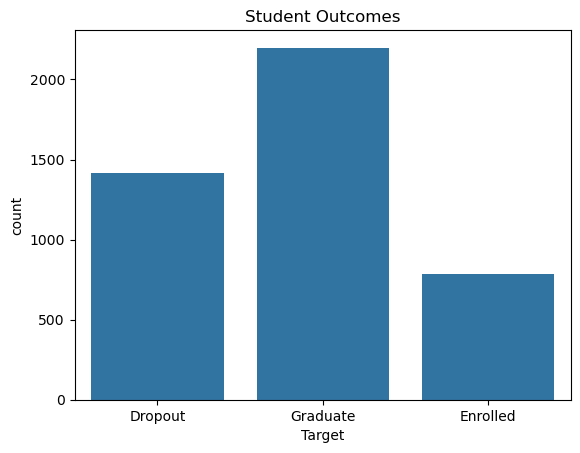

In [143]:
sns.countplot(
    data=df,
    x="Target")

plt.title("Student Outcomes")

Text(0.5, 1.0, 'Student maritial status')

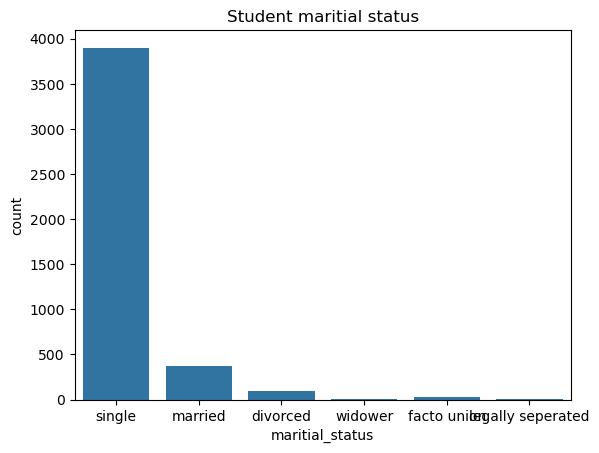

In [144]:
sns.countplot(
    data=df,
    x="maritial_status")

plt.title("Student maritial status")